# 1.П3. Тестирование в оффлайн

> **Модуль:** A/B тестирование · **Блок:** практический · **Время:** 3 ч · **Опирается на:** 1.02, 1.04, 1.П2

В онлайне пользователей тысячи, а рандомизирует платформа. В оффлайне единица эксперимента — магазин: их мало, они все разные, а список пилотных точек часто составляет бизнес. В этой практике проведём два пилота на настоящей истории продаж и ответим на вопрос: **как получить честный вывод, когда магазинов десятки, а рандомизация под вопросом**.

**Что сделаем на практике**

1. **Очистим данные** и отберём магазины, пригодные для эксперимента.
2. **Измерим цену неверной единицы анализа** на A/A по истории.
3. **Сравним дизайны**: случайное разбиение, пары, учёт предпериода.
4. **Посчитаем мощность** инъекцией эффекта и узнаем, что важнее: магазины или недели.
5. **Проанализируем первую волну** со случайным назначением: эффект, трафик и чек, окупаемость, нехватка товара.
6. **Разберём вторую волну**, где магазины выбрал бизнес.
7. **Проверим сопоставимость групп**: PSI, плацебо, adversarial validation.
8. **Оценим ловушки оффлайна**: каннибализацию и перенос результата на сеть.
9. **Примем решение** и напишем регламент для команды.

Главный вывод практики: в оффлайне основная работа делается до старта, а значимость не отвечает на вопрос, окупится ли изменение.

Две темы мы используем раньше, чем они разбираются в курсе. Кластерные эксперименты подробно идут в лекции 2.03, разность разностей (DiD) и синтетический контроль — в лекции 2.09. Здесь хватит краткого объяснения, которое дано по месту.

## 0. Подготовка

### Библиотеки

In [1]:
from pathlib import Path
from urllib.parse import quote

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.optimize import nnls
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

BLUE, RED, GREEN, GRAY = "#4C72B0", "#C44E52", "#55A868", "#7F7F7F"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

### Легенда

Сеть дрогери хочет открыть в магазинах бьюти-зону с консультантом. Зона стоит денег каждую неделю, поэтому вопрос не в том, есть ли эффект, а в том, **окупается ли она**.

- **Первая волна.** Команда получила пул из 80 магазинов, где зону физически можно поставить, и право случайно выбрать 40 из них.
- **Вторая волна.** Директор по рознице не стал ждать и выбрал 40 магазинов сам.

**Что здесь настоящее.** История продаж: открытый датасет [Rossmann Store Sales](https://www.kaggle.com/competitions/rossmann-store-sales), дневные продажи и число покупателей 1115 магазинов за 2013–2015 годы. Единицы выручки в данных не указаны, поэтому говорим о денежных единицах.

**Что здесь придумано.** Сам пилот. Мы добавляем его эффект в настоящие продажи, поэтому знаем правду и в конце сверим с ней выводы. Маржа и стоимость зоны тоже допущения, в данных их нет. Сами данные в репозитории не лежат: ноутбук скачивает их с Kaggle через `kagglehub`, авторизация не нужна.

In [2]:
SEED = 2027
ALPHA = 0.05
POWER = 0.80
PRE_WEEKS = 12                     # недель до пилота
POST_WEEKS = 6                     # недель пилота
N_STORES = 40                      # магазинов в группе
WAVE1_START = pd.Timestamp("2015-02-02")
WAVE2_START = pd.Timestamp("2015-05-04")
MARGIN = 0.25                      # допущение легенды: доля маржи в выручке
ZONE_COST = 200                    # допущение легенды: стоимость зоны в неделю на магазин
Z_SUM = stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(POWER)

## 1. Данные и отбор магазинов

Сначала соберём продажи по неделям: день слишком шумный, а магазин мы всё равно анализируем как целое (почему, увидим в разделе 2).

In [3]:
try:
    import kagglehub
except ImportError:
    %pip install -q kagglehub
    import kagglehub

path = kagglehub.dataset_download("pratyushakar/rossmann-store-sales")
sales = pd.read_csv(f"{path}/train.csv", parse_dates=["Date"], low_memory=False)
store_info = pd.read_csv(f"{path}/store.csv").set_index("Store")

sales = sales[sales["Date"].between("2013-01-07", "2015-07-26")].copy()   # только полные недели
sales["week"] = sales["Date"].dt.to_period("W-SUN").dt.start_time
weekly = (sales.groupby(["week", "Store"])
          .agg(revenue=("Sales", "sum"), customers=("Customers", "sum"), open_days=("Open", "sum"))
          .reset_index())
print(f"Магазинов: {sales['Store'].nunique()}, недель: {weekly['week'].nunique()}, строк: {len(sales):,}")
weekly.head()

Магазинов: 1115, недель: 133, строк: 1,004,945


,week,Store,revenue,customers,open_days
0,2013-01-07,1,32952,3918,6
1,2013-01-07,2,32914,3746,6
2,2013-01-07,3,51567,4940,6
3,2013-01-07,4,60703,8260,6
4,2013-01-07,5,30588,3408,6


Эксперимент нельзя ставить на магазине, который закрывался или выпадал из данных: изменение его выручки объясняется не пилотом, а простоем. Бургер Кинг начинает подготовку теста именно с такой очистки.

Посмотрим на полноту данных: строка — магазин, столбец — неделя.

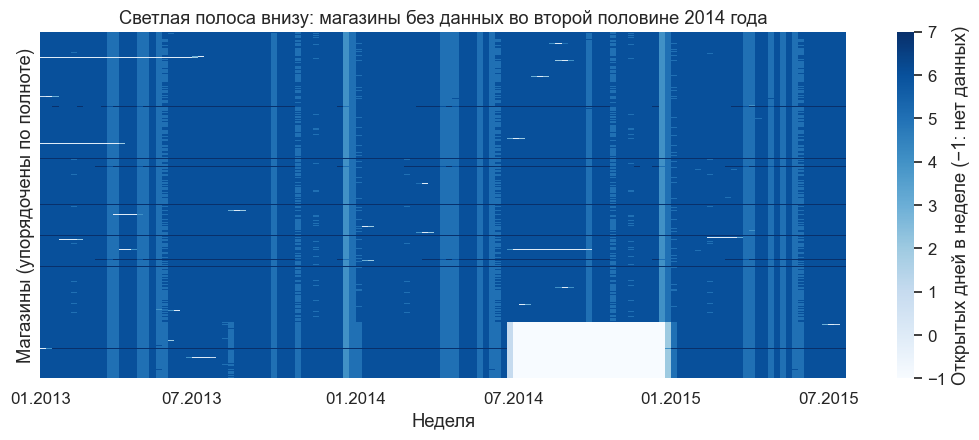

In [4]:
grid = weekly.pivot(index="Store", columns="week", values="open_days")
order = grid.notna().sum(axis=1).sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(grid.loc[order].fillna(-1).clip(upper=7), cmap="Blues", cbar_kws={"label": "Открытых дней в неделе (−1: нет данных)"},
            xticklabels=False, yticklabels=False, ax=ax)
ticks = [i for i, w in enumerate(grid.columns) if w.month in (1, 7) and w.day <= 7]
ax.set_xticks(ticks, [f"{grid.columns[i]:%m.%Y}" for i in ticks], rotation=0)
ax.set_xlabel("Неделя"); ax.set_ylabel("Магазины (упорядочены по полноте)")
ax.set_title("Светлая полоса внизу: магазины без данных во второй половине 2014 года")
plt.show()

### Задание 1. Отбор магазинов

Реализуйте `good_stores`: оставьте магазины, у которых **есть данные за каждую неделю**, выручка в каждую из них положительна и открытых дней не меньше `min_open_days`.

- Постройте сводные таблицы выручки и открытых дней (неделя × магазин).
- Пропуск должен исключать магазин, а сравнение с NaN и так даёт `False`.
- Верните индекс номеров магазинов.

In [5]:
def good_stores(weekly: pd.DataFrame, min_open_days: int = 4) -> pd.Index:
    # ВАШ КОД
    raise NotImplementedError

In [6]:
# @title Решение (нажмите, чтобы раскрыть)
def good_stores(weekly: pd.DataFrame, min_open_days: int = 4) -> pd.Index:
    revenue = weekly.pivot(index="week", columns="Store", values="revenue")
    open_days = weekly.pivot(index="week", columns="Store", values="open_days")
    good = (revenue > 0).all() & (open_days >= min_open_days).all()
    return revenue.columns[good]

In [7]:
# Проверка
good = good_stores(weekly)
assert len(good) == 855, "Должно остаться 855 магазинов"
assert 13 not in good, "Магазин 13 выпадает: у него нет данных за полгода"
print(f"Осталось {len(good)} из {weekly['Store'].nunique()} магазинов")

Осталось 855 из 1115 магазинов


Для всего дальнейшего возьмём логарифм выручки: разность логарифмов — почти процентное изменение, а магазины разного размера становятся сравнимы. Заодно посчитаем, насколько магазины отличаются друг от друга.

In [8]:
revenue = weekly.pivot(index="week", columns="Store", values="revenue")[good]
customers = weekly.pivot(index="week", columns="Store", values="customers")[good]
y_rev, y_cust = np.log(revenue), np.log(customers)
Y, Y_CUST = y_rev.to_numpy(), y_cust.to_numpy()     # недели x магазины
WEEKS, STORES = y_rev.index, y_rev.columns.to_numpy()
N_WEEKS, N_ALL = Y.shape

opened = sales[sales["Store"].isin(good) & (sales["Open"] == 1) & (sales["Sales"] > 0)]
y_day = np.log(opened.pivot(index="Date", columns="Store", values="Sales")[good]).to_numpy()
DAY_WEEK = opened.groupby("Date")["week"].first().to_numpy()

between, within = Y.mean(axis=0).var(), (Y - Y.mean(axis=0)).var()
icc = between / (between + within)
print(f"Дисперсия логарифма недельной выручки: между магазинами {between:.3f}, внутри магазина {within:.3f}")
print(f"ICC = {icc:.2f}, эффект дизайна для 36 дней пилота: {1 + 35 * icc:.1f}")

Дисперсия логарифма недельной выручки: между магазинами 0.106, внутри магазина 0.038
ICC = 0.73, эффект дизайна для 36 дней пилота: 26.7


Различия между магазинами в 2.8 раза больше колебаний внутри магазина: **ICC 0.73**. Это внутриклассовая корреляция из лекции 2.03: наблюдения одного магазина очень похожи между собой. Для 36 рабочих дней эффект дизайна около 27: дней много, но независимой информации в них почти как в одном наблюдении на магазин.

## 2. Цена неверной единицы анализа

Самый соблазнительный ход в оффлайне — считать наблюдением магазино-день: из 80 магазинов за 6 недель получается почти 3000 строк. Проверим его так же, как X5 проверяет свои методы: **A/A на истории**. Берём случайную дату старта, два случайных набора магазинов, никакого пилота нет. Правильный тест должен срабатывать в 5% случаев.

### Задание 2. A/A на разных единицах

Реализуйте `aa_pvalue`: p-value t-теста Стьюдента (`stats.ttest_ind`) между группами за 6 недель псевдопилота, начиная с недели `t0`.

- `"день"`: все значения логарифма дневных продаж (`y_day`, строки которого соответствуют дням, неделя дня лежит в `DAY_WEEK`). Пропуски выбросьте.
- `"неделя"`: все значения матрицы `Y` за эти недели.
- `"магазин"`: среднее по неделям для каждого магазина, одно число на магазин.

`treated` и `control` — номера столбцов магазинов.

In [9]:
def aa_pvalue(level: str, t0: int, treated: np.ndarray, control: np.ndarray) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [10]:
# @title Решение (нажмите, чтобы раскрыть)
def aa_pvalue(level: str, t0: int, treated: np.ndarray, control: np.ndarray) -> float:
    post = Y[t0:t0 + POST_WEEKS]
    if level == "день":
        days = y_day[np.isin(DAY_WEEK, WEEKS[t0:t0 + POST_WEEKS])]
        a, b = days[:, treated].ravel(), days[:, control].ravel()
        a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    elif level == "неделя":
        a, b = post[:, treated].ravel(), post[:, control].ravel()
    elif level == "магазин":
        a, b = post[:, treated].mean(axis=0), post[:, control].mean(axis=0)
    else:
        raise ValueError(level)
    return stats.ttest_ind(a, b).pvalue

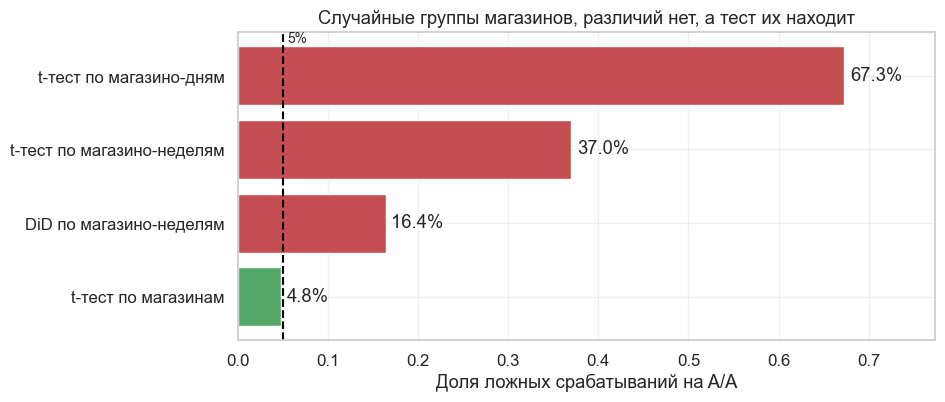

In [11]:
def random_window(rng, post: int = POST_WEEKS, pre: int = PRE_WEEKS) -> int:
    """Случайная дата старта псевдопилота в истории."""
    return int(rng.integers(pre, N_WEEKS - post + 1))


def did_iid_pvalue(t0: int, treated: np.ndarray, control: np.ndarray) -> float:
    """DiD по магазино-неделям с ошибками, будто наблюдения независимы."""
    idx = np.r_[treated, control]
    m = Y[t0 - PRE_WEEKS:t0 + POST_WEEKS, idx]
    m = m - m.mean(axis=0, keepdims=True) - m.mean(axis=1, keepdims=True) + m.mean()
    k = len(treated)
    effect = m[PRE_WEEKS:, :k].mean() - m[PRE_WEEKS:, k:].mean() - m[:PRE_WEEKS, :k].mean() + m[:PRE_WEEKS, k:].mean()
    se = m.std() * np.sqrt(2 / (POST_WEEKS * k) + 2 / (PRE_WEEKS * k))
    return 2 * stats.norm.sf(abs(effect / se))


def aa_fpr(R: int = 1000, k: int = N_STORES, seed: int = SEED) -> pd.Series:
    rng = np.random.default_rng(seed)
    hits = {"день": 0, "неделя": 0, "DiD, неделя": 0, "магазин": 0}
    for _ in range(R):
        t0 = random_window(rng)
        idx = rng.choice(N_ALL, 2 * k, replace=False)
        treated, control = idx[:k], idx[k:]
        for level in ("день", "неделя", "магазин"):
            hits[level] += aa_pvalue(level, t0, treated, control) < ALPHA
        hits["DiD, неделя"] += did_iid_pvalue(t0, treated, control) < ALPHA
    return pd.Series(hits) / R


fpr = aa_fpr()
assert fpr["день"] > 0.4 and fpr["неделя"] > 0.2, "Наивные тесты должны сильно завышать ошибку"
assert 0.03 < fpr["магазин"] < 0.07, "На уровне магазина должно быть около 5%"
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(["t-тест по магазино-дням", "t-тест по магазино-неделям", "DiD по магазино-неделям", "t-тест по магазинам"][::-1],
               fpr.values[::-1], color=[GREEN, RED, RED, RED])
ax.bar_label(bars, labels=[f"{v:.1%}" for v in fpr.values[::-1]], padding=4)
ax.axvline(ALPHA, color="black", linestyle="--"); ax.text(ALPHA + 0.005, 3.45, "5%", fontsize=10)
ax.set_xlim(0, fpr.max() * 1.15); ax.set_xlabel("Доля ложных срабатываний на A/A")
ax.set_title("Случайные группы магазинов, различий нет, а тест их находит")
plt.show()

Группы магазинов одинаковы по построению, а t-тест по магазино-дням находит различие в **67%** случаев, по магазино-неделям в **37%**. Магазин дважды попадает в данные как независимое наблюдение, хотя это один и тот же магазин.

Не спасает и DiD, если считать его по строкам с обычными ошибками: **16%**. Это классический результат Бертрана, Дюфло и Муллайнатана: недели одного магазина автокоррелированы, и ошибки надо считать на уровне единицы рандомизации.

Правило: **единица анализа совпадает с единицей рандомизации**. Рандомизировали магазины, значит, в тесте одно число на магазин. Подробнее об этом — в лекции 2.03.

Обратите внимание: дни и недели можно использовать, чтобы точнее посчитать число на магазин. Нельзя делать вид, что их независимо много.

## 3. Дизайн: что на самом деле снижает разброс

Магазинов мало, поэтому дизайн решает всё. Сравним четыре варианта.

- **Только пилот.** Сравниваем средние за пилот.
- **DiD (разность разностей).** Для каждого магазина считаем изменение $\Delta_i = \bar y_i^{\text{пилот}} - \bar y_i^{\text{до}}$ и сравниваем изменения между группами. Магазин служит сам себе контролем.
- **CUPED** из лекции 1.04: вычитаем $\theta \bar y_i^{\text{до}}$. При $\theta = 1$ это ровно DiD.
- **Пары.** Похожие магазины объединяем в пары и внутри пары случайно выбираем пилотный. Так советуют Imai, King и Nall, и так подбирают группы X5 и М.Видео.

### Задание 3. Подбор пар

Реализуйте `make_pairs(features)`: жадное построение пар по евклидову расстоянию. На вход матрица объектов × признаков, на выход массив формы `(число пар, 2)` с номерами строк.

1. Посчитайте матрицу квадратов расстояний, на диагонали поставьте `np.inf`.
2. Переберите объекты по возрастанию расстояния до ближайшего соседа.
3. Если объект свободен, соедините его с ближайшим свободным.

Жадный алгоритм не оптимален, но для нашей задачи этого достаточно.

In [12]:
def make_pairs(features: np.ndarray) -> np.ndarray:
    # ВАШ КОД
    raise NotImplementedError

In [13]:
# @title Решение (нажмите, чтобы раскрыть)
def make_pairs(features: np.ndarray) -> np.ndarray:
    dist = ((features[:, None] - features[None]) ** 2).sum(axis=2).astype(float)
    np.fill_diagonal(dist, np.inf)
    used = np.zeros(len(features), bool)
    pairs = []
    for i in np.argsort(dist.min(axis=1)):
        if used[i]:
            continue
        candidates = np.where(used, np.inf, dist[i])
        j = int(candidates.argmin())
        if np.isfinite(candidates[j]):
            used[i] = used[j] = True
            pairs.append((i, j))
    return np.array(pairs)

In [14]:
# Проверка
toy = np.array([[0.0], [10.0], [0.1], [10.2]])
pairs_toy = make_pairs(toy)
assert sorted(map(sorted, pairs_toy.tolist())) == [[0, 2], [1, 3]], "Должны сложиться пары (0, 2) и (1, 3)"
assert make_pairs(np.arange(6.0)[:, None]).shape == (3, 2)
print("Пары строятся верно")

Пары строятся верно


Теперь сравним дизайны на истории. Пары строим двумя способами: только по уровню продаж и по уровню вместе с формой кривой за 12 недель.

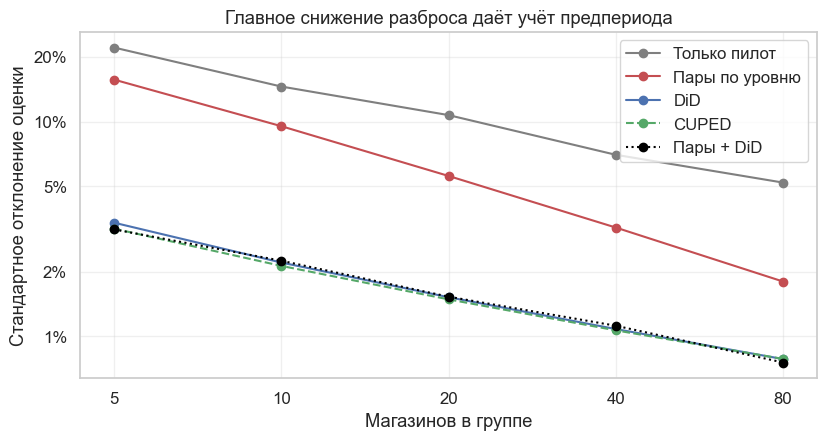

,Только пилот,Пары по уровню,DiD,CUPED,Пары + DiD
Магазинов в группе,,,,,
5,22.120,15.690,3.380,3.170,3.150
10,14.560,9.520,2.210,2.130,2.250
20,10.720,5.580,1.520,1.490,1.530
40,7.000,3.210,1.080,1.070,1.120
80,5.200,1.800,0.780,0.790,0.760


In [15]:
def store_features(pre: np.ndarray) -> np.ndarray:
    """Уровень продаж с весом 3 и форма кривой за предпериод."""
    level = pre.mean(axis=0)
    return np.c_[3 * level, (pre - level).T]


def design_spread(k: int, R: int = 600, seed: int = SEED) -> dict:
    rng = np.random.default_rng(seed)
    out = {name: [] for name in ("Только пилот", "Пары по уровню", "DiD", "CUPED", "Пары + DiD")}
    for _ in range(R):
        t0 = random_window(rng)
        idx = rng.choice(N_ALL, 2 * k, replace=False)
        pre, post = Y[t0 - PRE_WEEKS:t0, idx], Y[t0:t0 + POST_WEEKS, idx]
        after, before = post.mean(axis=0), pre.mean(axis=0)
        delta = after - before
        cuped = after - np.polyfit(before, after, 1)[0] * before
        order = rng.permutation(2 * k)
        t, c = order[:k], order[k:]
        out["Только пилот"].append(after[t].mean() - after[c].mean())
        out["DiD"].append(delta[t].mean() - delta[c].mean())
        out["CUPED"].append(cuped[t].mean() - cuped[c].mean())
        p = make_pairs(before[:, None])
        out["Пары по уровню"].append((rng.choice([-1, 1], len(p)) * (after[p[:, 0]] - after[p[:, 1]])).mean())
        p = make_pairs(store_features(pre))
        out["Пары + DiD"].append((rng.choice([-1, 1], len(p)) * (delta[p[:, 0]] - delta[p[:, 1]])).mean())
    return {name: 100 * np.std(v) for name, v in out.items()}


spread = pd.DataFrame({k: design_spread(k) for k in (5, 10, 20, 40, 80)}).T
spread.index.name = "Магазинов в группе"
fig, ax = plt.subplots(figsize=(9.5, 4.5))
colors = {"Только пилот": GRAY, "Пары по уровню": RED, "DiD": BLUE, "CUPED": GREEN, "Пары + DiD": "black"}
styles = {"CUPED": "--", "Пары + DiD": ":"}
for name in spread:
    ax.plot(spread.index, spread[name], marker="o", color=colors[name], linestyle=styles.get(name, "-"), label=name)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks(spread.index, spread.index); ax.minorticks_off()
ax.set_yticks([1, 2, 5, 10, 20], ["1%", "2%", "5%", "10%", "20%"])
ax.set_xlabel("Магазинов в группе"); ax.set_ylabel("Стандартное отклонение оценки")
ax.set_title("Главное снижение разброса даёт учёт предпериода"); ax.legend()
plt.show()
spread.round(2)

Главный результат виден сразу: **учёт предпериода снижает разброс оценки примерно в 6.5 раза** для 40 магазинов в группе (с 7.0% до 1.1%). Дисперсия падает примерно в 40 раз: большая часть различий между магазинами постоянна, и DiD её вычитает.

Без предпериода пары сильно помогают: разброс 3.2% против 7.0%. Это и есть результат из статей про парную рандомизацию. Но **поверх учёта предпериода пары на этих данных почти ничего не добавляют**: 1.1% против 1.1%. Они выравнивают постоянные различия, а их DiD уже убрал.

<details>
<summary><b>Зачем тогда вообще строить пары?</b> (нажмите, чтобы раскрыть)</summary>

Вывод относится к этим данным и этому способу подбора. Пары остаются полезны по трём причинам.

1. Они страхуют от случайного перекоса: при 5–10 магазинах в группе одно неудачное разбиение может собрать крупные магазины в одной группе.
2. Они дают простой анализ и понятное объяснение бизнесу: у каждого пилотного магазина есть свой контрольный.
3. Если предпериода нет (новые магазины) или метрика плохо коррелирует с прошлым, пары становятся главным инструментом.

В первой волне мы используем и пары, и предпериод: пары ничего не стоят.
</details>

### Пары и план на одних и тех же неделях

Chen et al. предупреждают: если пары подобраны и мощность оценена на одних данных, план получается слишком оптимистичным, потому что пары подстроились под шум этих недель. Проверим, насколько это важно здесь.

In [16]:
def pair_spread_in_out(k: int = N_STORES, R: int = 800, seed: int = SEED) -> pd.Series:
    """Разброс парной оценки на тех же неделях, что строили пары, и на следующих."""
    rng = np.random.default_rng(seed)
    half = PRE_WEEKS // 2
    inside, outside = [], []
    for _ in range(R):
        t0 = random_window(rng)
        idx = rng.choice(N_ALL, 2 * k, replace=False)
        pre = Y[t0 - PRE_WEEKS:t0, idx]
        p = make_pairs(store_features(pre))
        delta_in = pre[half:].mean(axis=0) - pre[:half].mean(axis=0)
        delta_out = Y[t0:t0 + half, idx].mean(axis=0) - pre[half:].mean(axis=0)
        signs = rng.choice([-1, 1], len(p))
        inside.append((signs * (delta_in[p[:, 0]] - delta_in[p[:, 1]])).mean())
        outside.append((signs * (delta_out[p[:, 0]] - delta_out[p[:, 1]])).mean())
    return 100 * pd.Series({"на неделях подбора": np.std(inside), "на следующих неделях": np.std(outside)})


overfit = pair_spread_in_out()
print("Разброс парной оценки, %:"); print(overfit.round(2).to_string())
print(f"Если считать план на неделях подбора, MDE окажется заниженным в {overfit.iloc[1] / overfit.iloc[0]:.2f} раза")

Разброс парной оценки, %:
на неделях подбора     0.950
на следующих неделях   1.020
Если считать план на неделях подбора, MDE окажется заниженным в 1.07 раза


Завышение есть, но скромное: разброс на следующих неделях всего на 7% больше, чем на неделях подбора. На 80 магазинах с такими признаками это не катастрофа, однако направление понятно. Правило простое и бесплатное: **подбираем пары на одном отрезке истории, а мощность считаем на другом**.

## 4. Мощность: инъекция эффекта вместо формулы

Формула из лекции 1.02 считает наблюдения независимыми, а мы уже знаем, что это не так. Поэтому X5 и М.Видео считают мощность прямо на истории:

1. Берём случайную дату старта и случайные группы.
2. Считаем оценку DiD. Её стандартное отклонение $\sigma_{\text{DiD}}$ по прогонам даёт $\text{MDE} = (z_{1-\alpha/2} + z_{1-\beta}) \cdot \sigma_{\text{DiD}}$.
3. Для проверки добавляем эффект в пилотную группу и смотрим, как часто тест его находит.

### Задание 4. Разброс и мощность по истории

Реализуйте две функции.

- `did_sd(k, post, R)`: $R$ раз выберите случайное окно (`random_window(rng, post=post)`) и $2k$ случайных магазинов, посчитайте для магазина изменение $\Delta_i$ (среднее за `post` недель минус среднее за `PRE_WEEKS` недель до них), затем разность средних $\Delta_i$ между половинами. Верните стандартное отклонение этих разностей.
- `injected_power(lift, k, post, R)`: то же самое, но прибавьте `lift` к изменениям пилотной половины и верните долю $p < \alpha$ в `stats.ttest_ind`.

In [17]:
def did_sd(k: int, post: int, R: int = 600, seed: int = SEED) -> float:
    # ВАШ КОД
    raise NotImplementedError


def injected_power(lift: float, k: int = N_STORES, post: int = POST_WEEKS, R: int = 1000, seed: int = SEED) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [18]:
# @title Решение (нажмите, чтобы раскрыть)
def did_sd(k: int, post: int, R: int = 600, seed: int = SEED) -> float:
    rng = np.random.default_rng(seed)
    effects = []
    for _ in range(R):
        t0 = random_window(rng, post=post)
        idx = rng.choice(N_ALL, 2 * k, replace=False)
        delta = Y[t0:t0 + post, idx].mean(axis=0) - Y[t0 - PRE_WEEKS:t0, idx].mean(axis=0)
        effects.append(delta[:k].mean() - delta[k:].mean())
    return float(np.std(effects))


def injected_power(lift: float, k: int = N_STORES, post: int = POST_WEEKS, R: int = 1000, seed: int = SEED) -> float:
    rng = np.random.default_rng(seed)
    hits = 0
    for _ in range(R):
        t0 = random_window(rng, post=post)
        idx = rng.choice(N_ALL, 2 * k, replace=False)
        delta = Y[t0:t0 + post, idx].mean(axis=0) - Y[t0 - PRE_WEEKS:t0, idx].mean(axis=0)
        hits += stats.ttest_ind(delta[:k] + lift, delta[k:]).pvalue < ALPHA
    return hits / R

In [19]:
# Проверка
sd_plan = did_sd(N_STORES, POST_WEEKS)
assert 0.009 < sd_plan < 0.014, "Разброс DiD для 40 + 40 и 6 недель около 1.2%"
power_a = injected_power(0.0, R=600)
power_b = injected_power(Z_SUM * sd_plan, R=600)
assert 0.03 < power_a < 0.07, "Без эффекта доля срабатываний около 5%"
assert 0.72 < power_b < 0.88, "На MDE мощность должна быть около 80%"
print(f"Разброс {sd_plan:.2%}, MDE {Z_SUM * sd_plan:.2%}, A/A {power_a:.3f}, мощность на MDE {power_b:.3f}")

Разброс 1.11%, MDE 3.11%, A/A 0.043, мощность на MDE 0.813


Посчитаем MDE для разных размеров пилота и его длительности. Справа — разброс изменения одного магазина в зависимости от длины пилота.

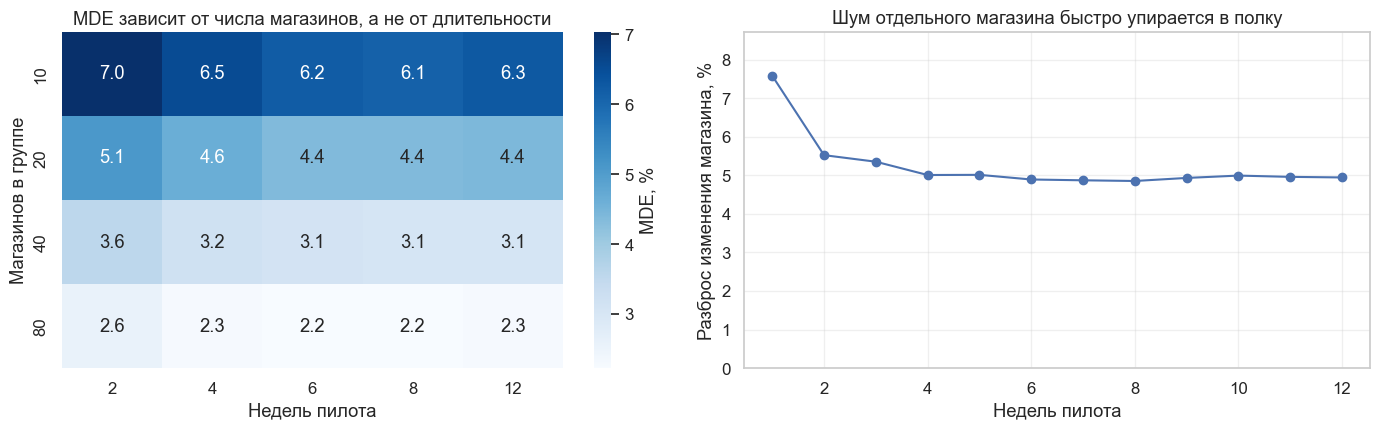

In [20]:
ks, posts = (10, 20, 40, 80), (2, 4, 6, 8, 12)
mde = pd.DataFrame({post: {k: 100 * Z_SUM * did_sd(k, post) for k in ks} for post in posts})
mde.index.name, mde.columns.name = "Магазинов в группе", "Недель пилота"

rng = np.random.default_rng(SEED)
store_sd = {}
for post in range(1, 13):
    values = []
    for _ in range(300):
        t0 = random_window(rng, post=post)
        delta = Y[t0:t0 + post].mean(axis=0) - Y[t0 - PRE_WEEKS:t0].mean(axis=0)
        values.append((delta - delta.mean()).std())
    store_sd[post] = 100 * np.mean(values)
store_sd = pd.Series(store_sd)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(mde, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "MDE, %"}, ax=axes[0])
axes[0].set_title("MDE зависит от числа магазинов, а не от длительности")
axes[1].plot(store_sd.index, store_sd.values, "-o", color=BLUE)
axes[1].set_ylim(0, store_sd.max() * 1.15)
axes[1].set_xlabel("Недель пилота"); axes[1].set_ylabel("Разброс изменения магазина, %")
axes[1].set_title("Шум отдельного магазина быстро упирается в полку")
plt.tight_layout(); plt.show()

Самый важный график для планирования оффлайн-пилота. **MDE почти не меняется после 4 недель**: при 40 магазинах в группе 3.2% за 4 недели и 3.1% за 12. Зато удвоение числа магазинов снижает его в $\sqrt{2}$ раз: 3.1% превращается в 2.2%.

Причина на правом графике. Шум магазина состоит из быстрой части (случайные недели), которая усредняется, и медленной (магазин сам по себе плывёт вверх или вниз), которая не усредняется, сколько бы мы ни ждали. После 4 недель остаётся только медленная часть.

В онлайне длинный тест компенсирует малый трафик. **В оффлайне мощность покупается магазинами, а не неделями.** Длинный пилот нужен по другим причинам: увидеть привыкание, захватить полный цикл закупки, но не ради мощности.

Обратите внимание, что это свойство данных: на других сетях и метриках кривая будет другой, поэтому такой расчёт делают заново для каждой задачи.

## 5. Первая волна: случайно внутри пар

Команда сделала всё правильно: подобрала 40 пар в пуле, бросила монетку в каждой, запустила зону 2 февраля 2015 года на 6 недель. Эффект добавляется в настоящие продажи пилотных магазинов.

Обратите внимание на состав пула: зону проще поставить в формате `a`, поэтому его там больше, чем в сети. Это вернётся в разделе 8.

In [21]:
LOCAL_PATH = Path("data/pilot_stores.csv")
REPO_PATH = "1. AB Тесты/Практический блок/03. Тестирование в оффлайн/data/pilot_stores.csv"
DATA_URL = "https://raw.githubusercontent.com/Alberelloo/Hypothesis-Testing-Course/main/" + quote(REPO_PATH)

pilot = pd.read_csv(LOCAL_PATH if LOCAL_PATH.exists() else DATA_URL).set_index("store").loc[STORES]
pool_idx = np.where(pilot["in_pool"] == 1)[0]
print(f"Пул первой волны: {len(pool_idx)} магазинов, форматы: {store_info.loc[STORES[pool_idx], 'StoreType'].value_counts().to_dict()}")
print(f"Вся сеть: {store_info.loc[STORES, 'StoreType'].value_counts().to_dict()}")

t1, t2 = WEEKS.get_loc(WAVE1_START), WEEKS.get_loc(WAVE2_START)

rng = np.random.default_rng(SEED)
pairs = pool_idx[make_pairs(store_features(Y[t1 - PRE_WEEKS:t1, pool_idx]))]
flip = rng.integers(0, 2, len(pairs)).astype(bool)
treated1 = np.where(flip, pairs[:, 0], pairs[:, 1])
control1 = np.where(flip, pairs[:, 1], pairs[:, 0])


def apply_pilot(matrix: np.ndarray, treated: np.ndarray, t0: int, uplift: np.ndarray, stockout: np.ndarray | None = None) -> np.ndarray:
    """Добавляет прирост в логарифмы показателей магазинов пилота."""
    result = matrix.copy()
    effect = np.tile(uplift[treated], (POST_WEEKS, 1))
    if stockout is not None:
        effect[2:4, stockout[treated]] = 0        # на 3-4 неделе зона пустая
    result[t0:t0 + POST_WEEKS, treated] += effect
    return result


traffic_up = pilot["traffic_uplift"].to_numpy()
check_up = pilot["check_uplift"].to_numpy()
stockout = pilot["stockout_if_treated"].to_numpy().astype(bool)
Y1 = apply_pilot(Y, treated1, t1, traffic_up + check_up, stockout)
Y1_CUST = apply_pilot(Y_CUST, treated1, t1, traffic_up, stockout)
print(f"Пар: {len(pairs)}, пилот {WEEKS[t1]:%d.%m.%Y} — {WEEKS[t1 + POST_WEEKS - 1] + pd.Timedelta(days=6):%d.%m.%Y}")

Пул первой волны: 80 магазинов, форматы: {'a': 60, 'd': 13, 'c': 6, 'b': 1}
Вся сеть: {'a': 469, 'd': 256, 'c': 120, 'b': 10}
Пар: 40, пилот 02.02.2015 — 15.03.2015


### Задание 5. Анализ пар

Реализуйте две функции.

- `paired_analysis(matrix, treated, control, t0)`: посчитайте $\Delta_i$ каждого магазина (6 недель с `t0` минус 12 недель до него) и разности внутри пар $d_j = \Delta_{\text{пилот}, j} - \Delta_{\text{контроль}, j}$. Верните словарь с ключами `effect`, `se`, `low`, `high`, `p`, `diffs`, где интервал и p-value из одновыборочного $t$-теста по $d_j$.
- `sign_flip_pvalue(diffs, R)`: перестановочный тест. Если эффекта нет, знак каждой $d_j$ определяется монеткой. Случайно меняйте знаки, считайте среднее и верните двустороннее p-value с поправкой $(1 + \#\{|\text{нуль}| \ge |\text{наблюдаемое}|\}) / (R + 1)$.

In [22]:
def paired_analysis(matrix: np.ndarray, treated: np.ndarray, control: np.ndarray, t0: int, alpha: float = ALPHA) -> dict:
    # ВАШ КОД
    raise NotImplementedError


def sign_flip_pvalue(diffs: np.ndarray, R: int = 20_000, seed: int = SEED) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [23]:
# @title Решение (нажмите, чтобы раскрыть)
def paired_analysis(matrix: np.ndarray, treated: np.ndarray, control: np.ndarray, t0: int, alpha: float = ALPHA) -> dict:
    delta = matrix[t0:t0 + POST_WEEKS].mean(axis=0) - matrix[t0 - PRE_WEEKS:t0].mean(axis=0)
    diffs = delta[treated] - delta[control]
    n = len(diffs)
    effect = diffs.mean()
    se = diffs.std(ddof=1) / np.sqrt(n)
    half = stats.t.ppf(1 - alpha / 2, n - 1) * se
    return {"effect": effect, "se": se, "low": effect - half, "high": effect + half,
            "p": 2 * stats.t.sf(abs(effect / se), n - 1), "diffs": diffs}


def sign_flip_pvalue(diffs: np.ndarray, R: int = 20_000, seed: int = SEED) -> float:
    rng = np.random.default_rng(seed)
    signs = rng.choice([-1, 1], (R, len(diffs)))
    null = (signs * diffs).mean(axis=1)
    return float((1 + (np.abs(null) >= abs(diffs.mean())).sum()) / (R + 1))

In [24]:
# Проверка
wave1 = paired_analysis(Y1, treated1, control1, t1)
placebo1 = paired_analysis(Y, treated1, control1, t1 - POST_WEEKS - 2)
perm_p = sign_flip_pvalue(wave1["diffs"])
assert abs(sign_flip_pvalue(np.array([1.0, -1.0, 1.0, -1.0]), R=5000) - 1) < 0.01, "Нулевой средний сдвиг даёт p около 1"
assert wave1["low"] < wave1["effect"] < wave1["high"]
assert abs(wave1["p"] - perm_p) < 0.02, "Два p-value должны быть близки"
print(f"Эффект на выручку: {wave1['effect']:+.2%} [{wave1['low']:+.2%}; {wave1['high']:+.2%}]")
print(f"p (t-тест по парам) = {wave1['p']:.4f}, p (перестановки) = {perm_p:.4f}")
print(f"Плацебо до пилота: {placebo1['effect']:+.2%} [{placebo1['low']:+.2%}; {placebo1['high']:+.2%}]")

Эффект на выручку: +2.31% [+0.46%; +4.16%]
p (t-тест по парам) = 0.0158, p (перестановки) = 0.0162
Плацебо до пилота: +0.66% [-1.01%; +2.34%]


Эффект значим: **+2.31% [+0.46%; +4.16%]**, p = 0.016. Плацебо на неделях до пилота чистое. Перестановочный тест дал то же самое: p = 0.016. Он опирается только на схему рандомизации и не требует нормальности, поэтому ему доверяют при малом числе кластеров, но на этих данных он с $t$-тестом не расходится. На A/A разницы тоже нет: при 5 и 8 магазинах в группе оба дают 3–4%.

Посмотрим на разность групп по неделям.

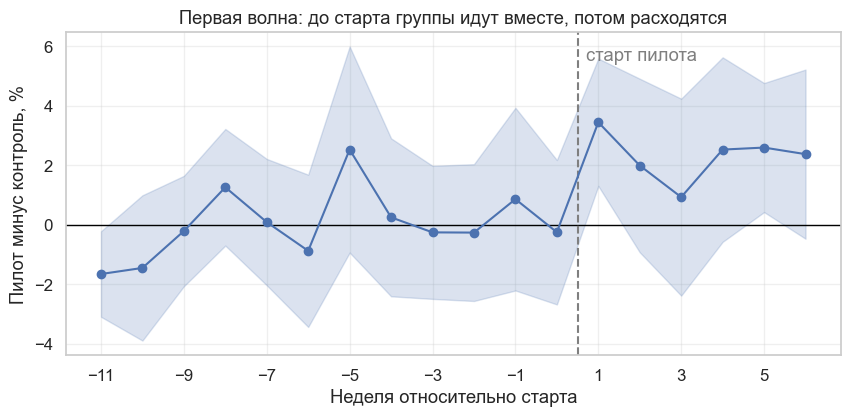

In [25]:
def weekly_gap(matrix, treated, control, t0, before=PRE_WEEKS, after=POST_WEEKS):
    """Разность групп по неделям относительно предпериода и её 95% интервал."""
    base = matrix[t0 - PRE_WEEKS:t0].mean(axis=0)
    weeks = np.arange(-before, after)
    d = (matrix[t0 - before:t0 + after] - base)[:, treated] - (matrix[t0 - before:t0 + after] - base)[:, control]
    return weeks + 1, d.mean(axis=1), stats.t.ppf(0.975, d.shape[1] - 1) * d.std(axis=1, ddof=1) / np.sqrt(d.shape[1])


x, gap, band = weekly_gap(Y1, treated1, control1, t1)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axhline(0, color="black", linewidth=1); ax.axvline(0.5, color=GRAY, linestyle="--")
ax.fill_between(x, 100 * (gap - band), 100 * (gap + band), color=BLUE, alpha=0.2)
ax.plot(x, 100 * gap, "-o", color=BLUE)
ax.text(0.7, ax.get_ylim()[1] * 0.85, "старт пилота", color=GRAY)
ax.set_xticks(np.arange(-11, 7, 2)); ax.set_xlabel("Неделя относительно старта"); ax.set_ylabel("Пилот минус контроль, %")
ax.set_title("Первая волна: до старта группы идут вместе, потом расходятся")
plt.show()

### Задание 6. Трафик и чек

Выручка равна числу покупателей, умноженному на средний чек, значит, в логарифмах $\log \text{выручка} = \log \text{трафик} + \log \text{чек}$. X5 подчёркивает, что смотреть надо на обе части: рост чека может сопровождаться падением посещений.

Реализуйте `decompose_revenue(rev, cust, treated, control, t0)`: примените `paired_analysis` к выручке, трафику (`cust`) и логарифму чека (`rev - cust`). Верните таблицу со строками «Выручка», «Трафик», «Средний чек» и столбцами `effect`, `se`, `low`, `high`, `p`.

In [26]:
def decompose_revenue(rev: np.ndarray, cust: np.ndarray, treated: np.ndarray, control: np.ndarray, t0: int) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [27]:
# @title Решение (нажмите, чтобы раскрыть)
def decompose_revenue(rev: np.ndarray, cust: np.ndarray, treated: np.ndarray, control: np.ndarray, t0: int) -> pd.DataFrame:
    parts = {"Выручка": rev, "Трафик": cust, "Средний чек": rev - cust}
    rows = {}
    for name, matrix in parts.items():
        res = paired_analysis(matrix, treated, control, t0)
        rows[name] = {k: res[k] for k in ("effect", "se", "low", "high", "p")}
    return pd.DataFrame(rows).T

In [28]:
# Проверка
parts1 = decompose_revenue(Y1, Y1_CUST, treated1, control1, t1)
gap_sum = parts1.loc["Трафик", "effect"] + parts1.loc["Средний чек", "effect"] - parts1.loc["Выручка", "effect"]
assert abs(gap_sum) < 1e-10, "В логарифмах трафик и чек складываются в выручку"
parts1.assign(**{c: parts1[c] * 100 for c in ("effect", "se", "low", "high")}).round(3)

,effect,se,low,high,p
Выручка,2.307,0.915,0.457,4.157,0.016
Трафик,-0.600,0.869,-2.358,1.158,0.494
Средний чек,2.907,0.468,1.960,3.854,0.000


Механика эффекта ясна: **чек +2.9% при разбросе всего 0.47%**, трафик не отличим от нуля. Метрика среднего чека вдвое точнее выручки, потому что шум магазинов сидит в основном в трафике. Если гипотеза про чек, основной метрикой стоит взять его, а выручку оставить для окупаемости.

Трафик здесь заслуживает отдельного внимания: минус 0.6% с интервалом до −2.4%. Значимости нет, но и отсутствие вреда не доказано: падение на 2% тоже укладывается в интервал.

### Задание 7. Окупаемость

Зона окупается, если дополнительная маржа за неделю покрывает её стоимость: $\text{маржа} \cdot \text{выручка} \cdot \tau \ge \text{стоимость}$.

- `breakeven_lift(margin, zone_cost, weekly_revenue)`: минимальный прирост выручки $\tau$.
- `rollout_decision(low, high, breakeven)`: верните `"окупается"`, если весь интервал выше порога, `"не окупается"`, если весь интервал ниже, иначе `"неясно"`.

In [29]:
def breakeven_lift(margin: float, zone_cost: float, weekly_revenue: float) -> float:
    # ВАШ КОД
    raise NotImplementedError


def rollout_decision(low: float, high: float, breakeven: float) -> str:
    # ВАШ КОД
    raise NotImplementedError

In [30]:
# @title Решение (нажмите, чтобы раскрыть)
def breakeven_lift(margin: float, zone_cost: float, weekly_revenue: float) -> float:
    return zone_cost / (margin * weekly_revenue)


def rollout_decision(low: float, high: float, breakeven: float) -> str:
    if low > breakeven:
        return "окупается"
    if high < breakeven:
        return "не окупается"
    return "неясно"

In [31]:
# Проверка
assert abs(breakeven_lift(0.25, 200, 40_000) - 0.02) < 1e-12
assert rollout_decision(0.03, 0.05, 0.02) == "окупается"
assert rollout_decision(-0.01, 0.01, 0.02) == "не окупается"
assert rollout_decision(0.01, 0.04, 0.02) == "неясно"
weekly_mean = revenue.iloc[:, pool_idx].loc[WEEKS[t1 - PRE_WEEKS:t1]].mean().mean()
BREAKEVEN = breakeven_lift(MARGIN, ZONE_COST, weekly_mean)
print(f"Средняя неделя магазина: {weekly_mean:,.0f}, порог окупаемости: {BREAKEVEN:.2%}")
print(f"Решение: {rollout_decision(wave1['low'], wave1['high'], BREAKEVEN)}")

Средняя неделя магазина: 43,622, порог окупаемости: 1.83%
Решение: неясно


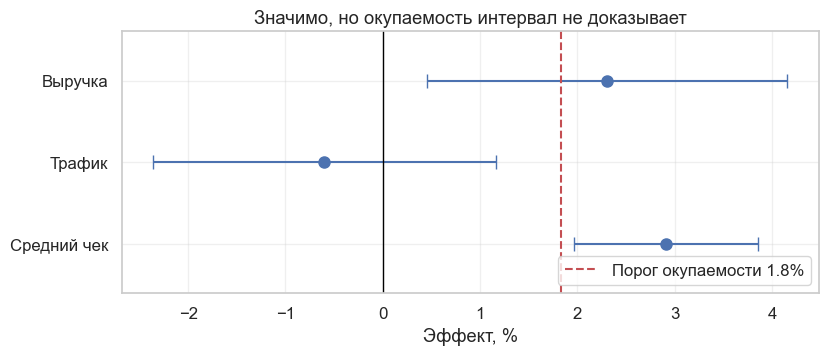

In [32]:
rows = parts1[["effect", "low", "high"]] * 100
fig, ax = plt.subplots(figsize=(9, 3.4))
ypos = np.arange(len(rows))[::-1]
ax.errorbar(rows["effect"], ypos, xerr=[rows["effect"] - rows["low"], rows["high"] - rows["effect"]],
            fmt="o", color=BLUE, capsize=5, markersize=8)
ax.axvline(0, color="black", linewidth=1)
ax.axvline(100 * BREAKEVEN, color=RED, linestyle="--", label=f"Порог окупаемости {BREAKEVEN:.1%}")
ax.set_yticks(ypos, rows.index); ax.set_ylim(-0.6, 2.6)
ax.set_xlabel("Эффект, %"); ax.set_title("Значимо, но окупаемость интервал не доказывает"); ax.legend(loc="lower right")
plt.show()

Значимо, но **неясно**: порог 1.83% лежит внутри интервала. Проверка «отличается ли эффект от нуля» отвечала не на тот вопрос. Ноль здесь не интересен: зона с приростом в 1% значима при большом пилоте и всё равно убыточна.

Это прямое следствие плана: MDE 3.1% почти вдвое больше порога. Пилот на 40 + 40 **с самого начала не мог уверенно ответить на вопрос об окупаемости**. Чтобы сузить интервал шириной около $\pm 2\%$, нужно больше магазинов, а не больше недель. Эту сверку MDE с порогом делают до старта, а не после.

### Задание 8. Нехватка товара

Операционисты сообщили: на 3-й и 4-й неделях в самых крупных магазинах закончилась продукция для зоны. М.Видео описывает такую же проблему: успех зависит не только от идеи, но и от того, как её реализовали на полке.

Реализуйте `stockout_scenarios(matrix, treated, control, t0, hit)`, где `hit` — маска пар с пострадавшим пилотным магазином. Верните таблицу со столбцами `effect`, `low`, `high`, `пар` и строками:

- «Все пары (ITT)»;
- «Без пострадавших пар»;
- «Только пострадавшие пары»;
- «Выкинуть только пострадавшие пилотные магазины»: средняя $\Delta_i$ оставшихся пилотных минус средняя $\Delta_i$ **всего** контроля (интервал оставьте `NaN`).

In [33]:
def stockout_scenarios(matrix: np.ndarray, treated: np.ndarray, control: np.ndarray, t0: int, hit: np.ndarray) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [34]:
# @title Решение (нажмите, чтобы раскрыть)
def stockout_scenarios(matrix: np.ndarray, treated: np.ndarray, control: np.ndarray, t0: int, hit: np.ndarray) -> pd.DataFrame:
    keep = ~hit
    delta = matrix[t0:t0 + POST_WEEKS].mean(axis=0) - matrix[t0 - PRE_WEEKS:t0].mean(axis=0)
    only_treated = delta[treated[keep]].mean() - delta[control].mean()
    rows = {"Все пары (ITT)": paired_analysis(matrix, treated, control, t0),
            "Без пострадавших пар": paired_analysis(matrix, treated[keep], control[keep], t0),
            "Только пострадавшие пары": paired_analysis(matrix, treated[hit], control[hit], t0)}
    table = pd.DataFrame({k: {c: v[c] for c in ("effect", "low", "high")} | {"пар": len(v["diffs"])} for k, v in rows.items()}).T
    table.loc["Выкинуть только пострадавшие пилотные магазины"] = [only_treated, np.nan, np.nan, keep.sum()]
    return table

In [35]:
# Проверка
hit = stockout[treated1]
stock = stockout_scenarios(Y1, treated1, control1, t1, hit)
assert stock.loc["Все пары (ITT)", "пар"] == len(pairs)
assert stock.loc["Без пострадавших пар", "пар"] + stock.loc["Только пострадавшие пары", "пар"] == len(pairs)
print(f"Товар закончился в {hit.sum()} магазинах пилота из {len(treated1)}")
shown = stock.copy()
shown[["effect", "low", "high"]] *= 100
shown.round(2)

Товар закончился в 13 магазинах пилота из 40


,effect,low,high,пар
Все пары (ITT),2.310,0.460,4.160,40.000
Без пострадавших пар,2.630,0.500,4.770,27.000
Только пострадавшие пары,1.630,-2.420,5.680,13.000
Выкинуть только пострадавшие пилотные магазины,3.210,NaN,NaN,27.000


Сравним ответы.

- **ITT** (`intention to treat`, анализ всех назначенных) сохраняет рандомизацию и отвечает на вопрос «что будет, если раскатить зону с такими же сбоями». Это основная оценка.
- **Без пострадавших пар**: оценка выше, 2.6%, а рандомизация внутри оставшихся пар сохранена, хотя отвечает она уже на вопрос о магазинах не самого большого размера.
- **Выкинуть только пилотные магазины**: оценка самая высокая, 3.2%. Это ошибка: убрали крупные магазины только с одной стороны, и группы перестали быть сравнимы.

Здесь разница невелика, но если сбой связан с успехом (хорошо продаётся и потому заканчивается), такое исключение завышает эффект систематически. Правило: **не выбрасывайте магазины после старта по событиям внутри пилота**. Сбой чинят в операционке и учитывают отдельным сценарием.

## 6. Вторая волна: магазины выбрал бизнес

Директор сказал: «Я знаю, какие магазины сильные» — и назначил зону в 40 точек из отчёта, с которым работает ещё с 2013 года. Рандомизации нет. Это не редкость: в Бургер Кинге тестовую группу выбирают фильтрами, а контроль подбирают мэтчингом, и автор статьи прямо пишет, что офлайн-тесты ближе к причинно-следственному анализу, чем к классическому A/B.

Контролем служат все остальные магазины, кроме участников первой волны: у них зона уже стоит. Первая мысль — посчитать тот же DiD.

In [36]:
business_idx = np.where(pilot["business_list"] == 1)[0]
exclude = np.r_[business_idx, treated1]                 # магазины первой волны уже с зоной
rest2 = np.setdiff1d(np.arange(N_ALL), exclude)

Y2 = apply_pilot(Y1, business_idx, t2, traffic_up + check_up)
Y2_CUST = apply_pilot(Y1_CUST, business_idx, t2, traffic_up)
print(f"Вторая волна: {len(business_idx)} магазинов из списка директора, контроль: {len(rest2)}")
print(f"Форматы списка: {store_info.loc[STORES[business_idx], 'StoreType'].value_counts().to_dict()}")
print(f"Даты: {WEEKS[t2]:%d.%m.%Y} — {WEEKS[t2 + POST_WEEKS - 1] + pd.Timedelta(days=6):%d.%m.%Y}")

Вторая волна: 40 магазинов из списка директора, контроль: 775
Форматы списка: {'a': 24, 'd': 12, 'c': 4}
Даты: 04.05.2015 — 14.06.2015


### Задание 9. DiD и плацебо

Реализуйте `did_estimate(matrix, treated, control, t0)`: разность средних $\Delta_i$ между группами, ошибка $\sqrt{s_T^2 / n_T + s_C^2 / n_C}$ и интервал $\pm 1.96 \cdot \text{se}$. Верните словарь с ключами `effect`, `se`, `low`, `high`.

Проверочная ячейка применит её к пилоту и к тем же датам год назад, когда зоны ещё не было. Это плацебо по времени.

In [37]:
def did_estimate(matrix: np.ndarray, treated: np.ndarray, control: np.ndarray, t0: int) -> dict:
    # ВАШ КОД
    raise NotImplementedError

In [38]:
# @title Решение (нажмите, чтобы раскрыть)
def did_estimate(matrix: np.ndarray, treated: np.ndarray, control: np.ndarray, t0: int) -> dict:
    delta = matrix[t0:t0 + POST_WEEKS].mean(axis=0) - matrix[t0 - PRE_WEEKS:t0].mean(axis=0)
    a, b = delta[treated], delta[control]
    effect = a.mean() - b.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    return {"effect": effect, "se": se, "low": effect - 1.96 * se, "high": effect + 1.96 * se}

In [39]:
# Проверка
naive2 = did_estimate(Y2, business_idx, rest2, t2)
placebo2 = did_estimate(Y2, business_idx, rest2, t2 - 52)
assert naive2["low"] > BREAKEVEN, "Наивная оценка должна выглядеть как победа"
assert placebo2["low"] > 0, "Плацебо год назад должно тоже показать рост"
print(f"Вторая волна, DiD: {naive2['effect']:+.2%} [{naive2['low']:+.2%}; {naive2['high']:+.2%}]")
print(f"Те же даты год назад, зоны нет: {placebo2['effect']:+.2%} [{placebo2['low']:+.2%}; {placebo2['high']:+.2%}]")

Вторая волна, DiD: +10.88% [+7.73%; +14.02%]
Те же даты год назад, зоны нет: +6.64% [+4.12%; +9.16%]


Директор доволен: **+10.9% [+7.7%; +14.0%]**. Но те же даты год назад, когда зоны не существовало, дают **+6.6%** со столь же уверенным интервалом. Посмотрим почему.

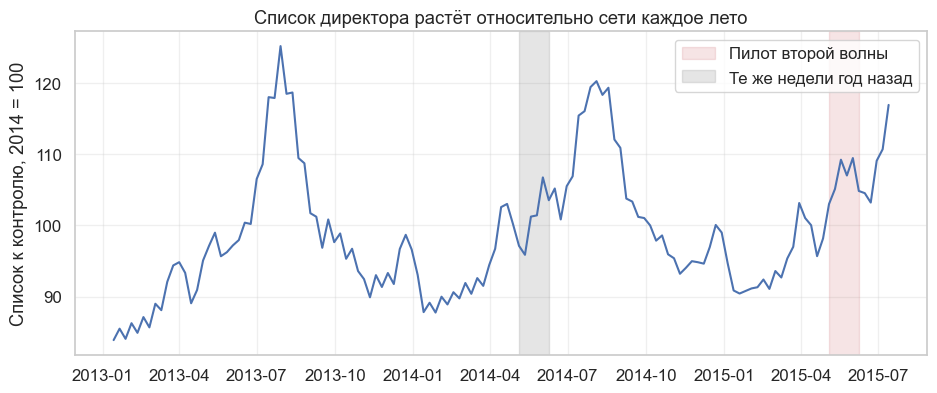

In [40]:
season = np.exp(Y2[:, business_idx]).sum(axis=1) / np.exp(Y2[:, rest2]).sum(axis=1)
season = pd.Series(season, index=WEEKS)
season = 100 * season / season.loc["2014-01-01":"2014-12-31"].mean()
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(season.index, season.rolling(3, center=True).mean(), color=BLUE)
ax.axvspan(WEEKS[t2], WEEKS[t2 + POST_WEEKS - 1], color=RED, alpha=0.15, label="Пилот второй волны")
ax.axvspan(WEEKS[t2 - 52], WEEKS[t2 - 52 + POST_WEEKS - 1], color=GRAY, alpha=0.2, label="Те же недели год назад")
ax.set_ylabel("Список к контролю, 2014 = 100")
ax.set_title("Список директора растёт относительно сети каждое лето"); ax.legend()
plt.show()

В списке директора оказались магазины с сильным летним пиком: они каждый год обгоняют сеть с мая по август. DiD держится на **параллельности трендов**: без пилота группы менялись бы одинаково. Здесь это неверно: пилот пришёлся на сезонный рост. Метки «курортный магазин» в данных нет, мы видим только форму продаж, но для анализа важна именно она.

Интервал +7.7…+14.0 честно описывает случайную ошибку и ничего не говорит о смещении. **Смещение не уменьшается от роста выборки.**

### Задание 10. Как исправить оценку

Попробуем то, что первым приходит в голову: подобрать контроль получше. И сравним с поправкой на прошлый год.

- `match_controls(features, treated, candidates)`: для каждого пилотного магазина выберите ближайшего по расстоянию кандидата без повторов. Верните номера выбранных магазинов.
- `yoy_estimate(matrix, treated, control, t0)`: посчитайте $\Delta_i$ сейчас и $\Delta_i$ на тех же неделях год назад (сдвиг на 52 недели), затем `did_estimate`-подобную оценку по их разности. Это разность разностей разностей: из изменения вычитаем обычное сезонное изменение того же магазина.

Синтетический контроль из лекции 2.09 дан готовым: он подбирает смесь магазинов, которая повторяет кривую списка до старта.

In [41]:
def match_controls(features: np.ndarray, treated: np.ndarray, candidates: np.ndarray) -> np.ndarray:
    # ВАШ КОД
    raise NotImplementedError


def yoy_estimate(matrix: np.ndarray, treated: np.ndarray, control: np.ndarray, t0: int) -> dict:
    # ВАШ КОД
    raise NotImplementedError

In [42]:
# @title Решение (нажмите, чтобы раскрыть)
def match_controls(features: np.ndarray, treated: np.ndarray, candidates: np.ndarray) -> np.ndarray:
    dist = ((features[treated][:, None] - features[candidates][None]) ** 2).sum(axis=2)
    taken, chosen = set(), []
    for row in dist:
        j = next(q for q in np.argsort(row) if q not in taken)
        taken.add(j)
        chosen.append(candidates[j])
    return np.array(chosen)


def yoy_estimate(matrix: np.ndarray, treated: np.ndarray, control: np.ndarray, t0: int) -> dict:
    now = matrix[t0:t0 + POST_WEEKS].mean(axis=0) - matrix[t0 - PRE_WEEKS:t0].mean(axis=0)
    last = matrix[t0 - 52:t0 - 52 + POST_WEEKS].mean(axis=0) - matrix[t0 - 52 - PRE_WEEKS:t0 - 52].mean(axis=0)
    delta = now - last
    a, b = delta[treated], delta[control]
    effect = a.mean() - b.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    return {"effect": effect, "se": se, "low": effect - 1.96 * se, "high": effect + 1.96 * se}

In [43]:
# Проверка
matched2 = match_controls(store_features(Y2[t2 - PRE_WEEKS:t2]), business_idx, rest2)
assert len(set(matched2)) == len(business_idx), "Контрольные магазины не должны повторяться"
assert not set(matched2) & set(business_idx)


def synth_effect(matrix: np.ndarray, treated: np.ndarray, candidates: np.ndarray, t0: int, weeks_back: int = 60) -> float:
    """Синтетический контроль: взвешенная смесь магазинов повторяет кривую списка до старта."""
    start = max(0, t0 - weeks_back)
    pre = matrix[start:t0] - matrix[start:t0].mean(axis=0)
    a = np.r_[pre[:, candidates], 100 * np.ones((1, len(candidates)))]
    w = nnls(a, np.r_[pre[:, treated].mean(axis=1), 100])[0]
    w = w / w.sum()
    gain = matrix[t0:t0 + POST_WEEKS].mean(axis=0) - matrix[start:t0].mean(axis=0)
    return gain[treated].mean() - (gain[candidates] * w).sum()


wave2_yoy = yoy_estimate(Y2, business_idx, rest2, t2)
estimates2 = pd.Series({
    "DiD со всей сетью": naive2["effect"],
    "DiD с мэтчингом": did_estimate(Y2, business_idx, matched2, t2)["effect"],
    "Синтетический контроль": synth_effect(Y2, business_idx, rest2, t2),
    "Коррекция на прошлый год": wave2_yoy["effect"],
})
print(f"С коррекцией: {wave2_yoy['effect']:+.2%} [{wave2_yoy['low']:+.2%}; {wave2_yoy['high']:+.2%}]")
(estimates2 * 100).round(2).to_frame("Оценка второй волны, %")

С коррекцией: +4.24% [+3.01%; +5.47%]


,"Оценка второй волны, %"
DiD со всей сетью,10.880
DiD с мэтчингом,10.770
Синтетический контроль,8.390
Коррекция на прошлый год,4.240


Мэтчинг почти не изменил оценку (+10.8%): он подбирает контроль по неделям перед стартом, а тогда магазины списка и правда похожи на остальные. Различие проявляется позже. Синтетический контроль смотрит на 60 недель назад и видел прошлое лето, но и он снизил оценку только до +8.4%. Поправка на прошлый год дала **+4.2%**: она прямо вычитает то, как эти магазины ведут себя в сезон.

Чтобы судить о методах, а не об одной оценке, проверим их на A/A, где правильный ответ равен нулю. Заодно посмотрим на второе правило отбора, очень частое в бизнесе: «поставим в те магазины, что сейчас растут».

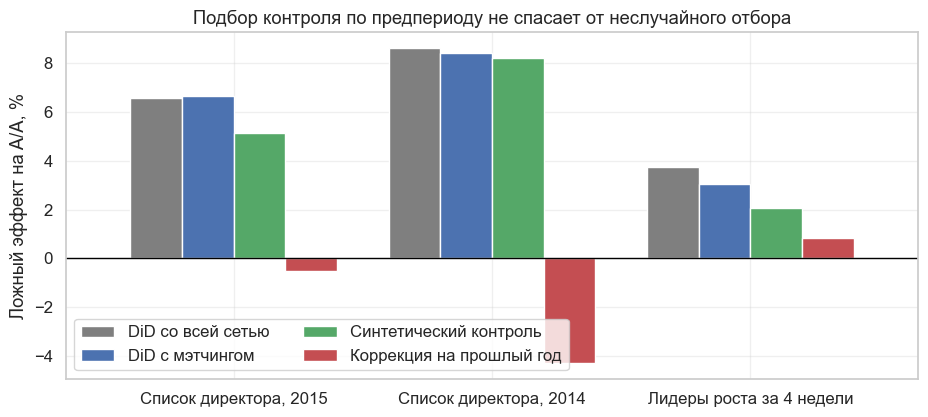

,"Список директора, 2015","Список директора, 2014",Лидеры роста за 4 недели
DiD со всей сетью,6.570,8.620,3.760
DiD с мэтчингом,6.670,8.430,3.060
Синтетический контроль,5.120,8.220,2.070
Коррекция на прошлый год,-0.500,-4.290,0.850


In [44]:
def bias_table() -> pd.DataFrame:
    """Смещение методов на A/A: зоны нет, правильный ответ равен нулю."""
    rest = np.setdiff1d(np.arange(N_ALL), business_idx)

    def methods(t0, treated, candidates):
        matched = match_controls(store_features(Y[t0 - PRE_WEEKS:t0]), treated, candidates)
        return {"DiD со всей сетью": did_estimate(Y, treated, candidates, t0)["effect"],
                "DiD с мэтчингом": did_estimate(Y, treated, matched, t0)["effect"],
                "Синтетический контроль": synth_effect(Y, treated, candidates, t0),
                "Коррекция на прошлый год": yoy_estimate(Y, treated, candidates, t0)["effect"]}

    rows = {}
    w15 = [i for i, w in enumerate(WEEKS) if pd.Timestamp("2015-05-04") <= w <= pd.Timestamp("2015-06-15")]
    w14 = [i for i, w in enumerate(WEEKS) if pd.Timestamp("2014-06-02") <= w <= pd.Timestamp("2014-07-07")]
    rows["Список директора, 2015"] = pd.DataFrame([methods(t, business_idx, rest) for t in w15]).mean()
    rows["Список директора, 2014"] = pd.DataFrame([methods(t, business_idx, rest) for t in w14]).mean()
    grow = []
    for t in range(PRE_WEEKS + 53, N_WEEKS - POST_WEEKS, 2):
        rise = Y[t - 4:t].mean(axis=0) - Y[t - PRE_WEEKS:t - 4].mean(axis=0)
        leaders = np.argsort(-rise)[:N_STORES]
        grow.append(methods(t, leaders, np.setdiff1d(np.arange(N_ALL), leaders)))
    rows["Лидеры роста за 4 недели"] = pd.DataFrame(grow).mean()
    return 100 * pd.DataFrame(rows)


bias = bias_table()
fig, ax = plt.subplots(figsize=(11, 4.5))
bias.T.plot.bar(ax=ax, color=[GRAY, BLUE, GREEN, RED], width=0.8, edgecolor="white", rot=0)
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Ложный эффект на A/A, %"); ax.set_xlabel("")
ax.set_title("Подбор контроля по предпериоду не спасает от неслучайного отбора"); ax.legend(ncol=2)
plt.show()
bias.round(2)

Что видно в таблице.

- **Подбор контроля не лечит неслучайный отбор.** Смещение DiD на списке директора в 2015 году +6.6%, с мэтчингом +6.7%, с синтетическим контролем +5.1%. Методы выравнивают то, что было до старта, а причина смещения приходит после.
- **Поправка на прошлый год работает, но только на независимой базе.** В 2015 году базой служит 2014-й, и смещение −0.5%. В 2014 году база — 2013-й, тот самый год, по которому директор отбирал магазины. Туда попали те, у кого пик 2013 года был случайно высоким, и поправка переборщила: **−4.3%**. Это возврат к среднему.
- **Лидеры роста** дают ложные +3.8%. Их рост случился ещё до старта: примерно треть скачка потом откатывается (это возврат к среднему), но остальное остаётся, а база за 12 недель скачок почти не содержит. DiD приписывает пилоту то, что произошло до него. Подбор уменьшает смещение, но не убирает его; лучше всех снова годовая поправка, +0.9%.

Наша оценка второй волны построена на независимой базе, но её интервал +3.0…+5.5 тоже не стоит воспринимать буквально: он учитывает только случайный разброс между магазинами. Поправка от окна к окну колеблется примерно на 0.9%, и остаточное смещение не исчезает.

Вывод: **никакая обработка не заменяет рандомизацию**. Если магазины выбраны заранее, ваш инструмент не метод, а проверка: плацебо и годовая база. Ниже разберём, как их использовать.

## 7. Проверка сопоставимости групп

Хорошо бы узнать о проблеме до старта. Команды используют разные инструменты: Бургер Кинг сравнивает группы через PSI, $t$-тесты и графики, а МТС предлагает adversarial validation: обучить классификатор отличать одну группу от другой. Если ROC AUC около 0.5, группы неразличимы.

$$\text{PSI} = \sum_{b} (a_b - e_b) \ln \frac{a_b}{e_b},$$

где $e_b$ и $a_b$ — доли базовой и проверяемой групп в корзине $b$. Обычно PSI ниже 0.1 считают стабильным, выше 0.25 — серьёзным различием.

### Задание 11. PSI и adversarial validation

- `psi(expected, actual, bins)`: границы корзин — квантили `expected`, крайние границы бесконечны. Доли нулевых корзин обрежьте снизу значением `1e-4`.
- `adversarial_auc(features, group_a, group_b, seed)`: `GradientBoostingClassifier(n_estimators=60, max_depth=2, random_state=seed)`, ROC AUC на 5-кратной кросс-валидации (`cross_val_score`).

Проверочная ячейка построит признаки: паспорт магазина, уровень, форму кривой и изменение год назад. Для сравнения она посчитает AUC на 100 случайных разбиениях, отдельно для признаков без прошлого года и с ним.

In [45]:
def psi(expected: np.ndarray, actual: np.ndarray, bins: int = 5) -> float:
    # ВАШ КОД
    raise NotImplementedError


def adversarial_auc(features: np.ndarray, group_a: np.ndarray, group_b: np.ndarray, seed: int = SEED) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [46]:
# @title Решение (нажмите, чтобы раскрыть)
def psi(expected: np.ndarray, actual: np.ndarray, bins: int = 5) -> float:
    edges = np.quantile(expected, np.linspace(0, 1, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None)
    return float(((a - e) * np.log(a / e)).sum())


def adversarial_auc(features: np.ndarray, group_a: np.ndarray, group_b: np.ndarray, seed: int = SEED) -> float:
    idx = np.r_[group_a, group_b]
    label = np.r_[np.ones(len(group_a)), np.zeros(len(group_b))]
    model = GradientBoostingClassifier(n_estimators=60, max_depth=2, random_state=seed)
    return float(cross_val_score(model, features[idx], label, cv=5, scoring="roc_auc").mean())

In [47]:
# Проверка
base = np.random.default_rng(1).normal(size=2000)
assert psi(base, np.random.default_rng(2).normal(size=2000)) < 0.02, "Одинаковые распределения дают PSI около нуля"
assert psi(base, np.random.default_rng(3).normal(1, 1, 2000)) > 0.25, "Сдвиг на сигму даёт большой PSI"

info = store_info.loc[STORES]
passport = pd.get_dummies(info[["StoreType", "Assortment"]]).astype(float).assign(
    competition=np.log1p(info["CompetitionDistance"].fillna(info["CompetitionDistance"].median())).to_numpy(),
    promo2=info["Promo2"].to_numpy()).to_numpy()
level = Y[t2 - PRE_WEEKS:t2].mean(axis=0)
shape = (Y[t2 - PRE_WEEKS:t2] - level).T
last_year = Y[t2 - 52:t2 - 52 + POST_WEEKS].mean(axis=0) - Y[t2 - 52 - PRE_WEEKS:t2 - 52].mean(axis=0)
feat_pre = np.c_[passport, level, shape]
feat_year = np.c_[feat_pre, last_year]

rng = np.random.default_rng(SEED)
null_auc, null_year, null_psi = [], [], []
for _ in range(100):
    idx = rng.choice(N_ALL, 2 * N_STORES, replace=False)
    null_auc.append(adversarial_auc(feat_pre, idx[:N_STORES], idx[N_STORES:]))
    null_year.append(adversarial_auc(feat_year, idx[:N_STORES], idx[N_STORES:]))
    null_psi.append(psi(level, level[idx[:N_STORES]]))
null_auc, null_year, null_psi = map(np.array, (null_auc, null_year, null_psi))
random_ctrl = rng.choice(rest2, N_STORES, replace=False)
auc_table = pd.Series({
    "Первая волна: пилот и контроль": adversarial_auc(feat_pre, treated1, control1),
    "Список и случайный контроль": adversarial_auc(feat_pre, business_idx, random_ctrl),
    "Список и мэтчинг, признаки предпериода": adversarial_auc(feat_pre, business_idx, matched2),
    "Список и мэтчинг, плюс прошлый год": adversarial_auc(feat_year, business_idx, matched2),
})
nulls = [null_auc, null_auc, null_auc, null_year]
checks = pd.DataFrame({"AUC": auc_table, "p (перестановки)": [(1 + (n >= v).sum()) / 101 for n, v in zip(nulls, auc_table)]})
psi_year = psi(last_year[rest2], last_year[business_idx])
psi_level = psi(level[rest2], level[business_idx])
print(f"PSI списка к сети: уровень продаж {psi_level:.2f}, изменение год назад {psi_year:.2f}")
print(f"PSI случайной группы из 40 магазинов: медиана {np.median(null_psi):.2f}, 95-й перцентиль {np.quantile(null_psi, 0.95):.2f}")
checks.round(3)

PSI списка к сети: уровень продаж 0.38, изменение год назад 1.62
PSI случайной группы из 40 магазинов: медиана 0.09, 95-й перцентиль 0.25


,AUC,p (перестановки)
Первая волна: пилот и контроль,0.416,0.832
Список и случайный контроль,0.775,0.010
"Список и мэтчинг, признаки предпериода",0.634,0.079
"Список и мэтчинг, плюс прошлый год",0.755,0.010


**Группы первой волны** неотличимы от случайных: AUC 0.42. **Список директора** против случайного контроля выдаёт себя сразу.

Главная ловушка в третьей строке. После мэтчинга признаки предпериода почти перестают отличать список от контроля: AUC 0.63, p = 0.08. Команда бы решила, что группы хорошие. Но стоит добавить изменение год назад, и AUC поднимается до 0.76. **Проверка видит только то, что вы ей дали.** Сравнение по предпериоду не поймает различие, которое проявится позже.

PSI по изменению год назад равен 1.62 при пороге 0.25, по уровню продаж 0.38.

Посмотрим, как ведёт себя AUC при случайных разбиениях.

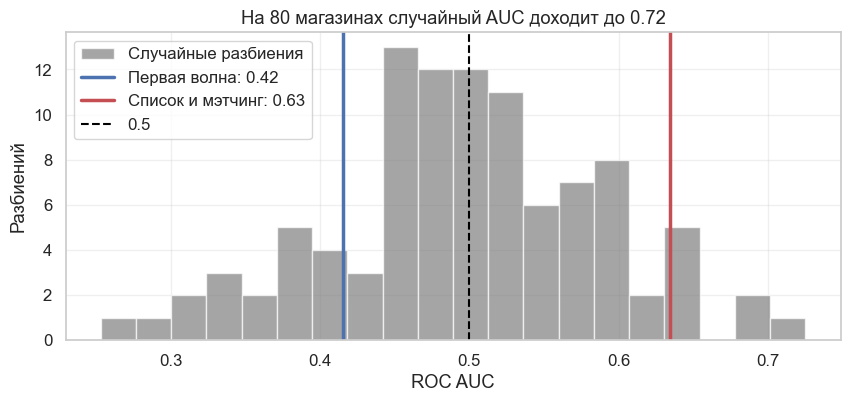

Случайные разбиения: среднее 0.50, от 0.25 до 0.72, 95-й перцентиль 0.65


In [48]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(null_auc, bins=20, color=GRAY, alpha=0.7, label="Случайные разбиения")
marks = {"Первая волна": (auc_table.iloc[0], BLUE), "Список и мэтчинг": (auc_table.iloc[2], RED)}
for name, (v, color) in marks.items():
    ax.axvline(v, color=color, linewidth=2.5, label=f"{name}: {v:.2f}")
ax.axvline(0.5, color="black", linestyle="--", label="0.5")
ax.set_xlabel("ROC AUC"); ax.set_ylabel("Разбиений")
ax.set_title(f"На 80 магазинах случайный AUC доходит до {null_auc.max():.2f}"); ax.legend()
plt.show()
print(f"Случайные разбиения: среднее {null_auc.mean():.2f}, от {null_auc.min():.2f} до {null_auc.max():.2f}, 95-й перцентиль {np.quantile(null_auc, 0.95):.2f}")

На 80 магазинах случайный AUC гуляет **от 0.25 до 0.72**, а не держится около 0.5. Ориентир «AUC ≈ 0.5» работает на больших выборках, а на десятках магазинов одно случайное разбиение легко выглядит подозрительным. Автор статьи и сам предупреждает, что у метода нет явной оценки мощности.

Правило: **сравнивайте AUC с распределением на случайных разбиениях тех же размеров**, а не с числом 0.5. По той же причине осторожно относитесь к порогам PSI на группе в 40 магазинов: у случайной группы медиана PSI 0.09, а 95-й перцентиль как раз 0.25.

## 8. Ловушки оффлайна

### Каннибализация

Покупатель выбирает ближайший магазин. Если в пилотном появилась зона, часть прироста приходит от соседей. Если сосед в контроле, он ещё и теряет. Подбор пар усугубляет дело: похожие магазины часто стоят рядом.

Пусть зона даёт магазину прирост $\tau$, и долю $s$ этого прироста он забирает у контрольного соседа. Тогда DiD покажет $\tau - (-s\tau) = \tau(1 + s)$, а сеть получит лишь $\tau(1 - s)$.

В наших данных географии нет, поэтому **ниже искусственный пример**: мы считаем, что контрольный магазин каждой пары стоит рядом с пилотным.

### Задание 12. Насколько завышается оценка

Реализуйте `spillover_overstatement(s)`: во сколько раз оценка DiD больше эффекта для сети.

In [49]:
def spillover_overstatement(s: float) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [50]:
# @title Решение (нажмите, чтобы раскрыть)
def spillover_overstatement(s: float) -> float:
    return (1 + s) / (1 - s)

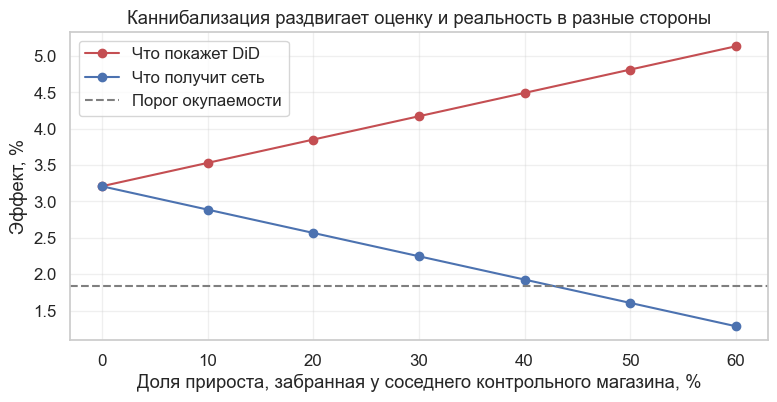

In [51]:
# Проверка
assert spillover_overstatement(0) == 1
assert abs(spillover_overstatement(0.5) - 3) < 1e-12

gross = traffic_up + check_up
rows = {}
for s in np.arange(0, 0.61, 0.1):
    # География вымышленная: считаем, что контрольный магазин пары стоит рядом с пилотным.
    moved = Y.copy()
    moved[t1:t1 + POST_WEEKS, treated1] += gross[treated1]
    moved[t1:t1 + POST_WEEKS, control1] -= s * gross[treated1]
    rows[s] = {"DiD": paired_analysis(moved, treated1, control1, t1)["effect"] - paired_analysis(Y, treated1, control1, t1)["effect"],
               "Эффект для сети": ((1 - s) * gross[treated1]).mean()}
spill = 100 * pd.DataFrame(rows).T
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(100 * spill.index, spill["DiD"], "-o", color=RED, label="Что покажет DiD")
ax.plot(100 * spill.index, spill["Эффект для сети"], "-o", color=BLUE, label="Что получит сеть")
ax.axhline(100 * BREAKEVEN, color=GRAY, linestyle="--", label="Порог окупаемости")
ax.set_xlabel("Доля прироста, забранная у соседнего контрольного магазина, %"); ax.set_ylabel("Эффект, %")
ax.set_title("Каннибализация раздвигает оценку и реальность в разные стороны"); ax.legend()
plt.show()

Оценка и реальность расходятся в разные стороны. При $s = 30\%$ DiD показывает 4.2%, а сеть получает 2.2%, почти вдвое меньше. При $s > 40\%$ реальный эффект уже ниже порога, а DiD продолжает расти.

На практике в дизайне пилота:

- Назначайте воздействие целым зонам обслуживания и держите **буфер** между пилотом и контролем, как в геоэкспериментах из лекции 2.03.
- Следите за выручкой магазинов рядом с пилотом, не входящих в эксперимент.
- Проверьте, не падает ли контроль относительно сети после старта.

### Перенос на сеть

X5 подчёркивает: в онлайне выводы обычно переносятся на всех пользователей, а в оффлайне нет. Наш пул состоит из формата `a` на 75%, а в сети его 55%. Если формат влияет на эффект, оценку нужно перевзвесить.

### Задание 13. Перевзвешивание по форматам

- `format_effects(matrix, treated, control, t0, is_a)`: примените `paired_analysis` отдельно к парам, где пилотный магазин формата `a`, и к остальным. Строки «Формат a» и «Другие форматы», столбцы `effect`, `se`, `low`, `high`, `пар`.
- `network_effect(table, share_a)`: эффект $w_a \tau_a + (1 - w_a) \tau_b$, ошибка $\sqrt{w_a^2 \text{se}_a^2 + (1 - w_a)^2 \text{se}_b^2}$, интервал $\pm 1.96 \cdot \text{se}$. Верните словарь с ключами `effect`, `se`, `low`, `high`.

In [52]:
def format_effects(matrix: np.ndarray, treated: np.ndarray, control: np.ndarray, t0: int, is_a: np.ndarray) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError


def network_effect(table: pd.DataFrame, share_a: float) -> dict:
    # ВАШ КОД
    raise NotImplementedError

In [53]:
# @title Решение (нажмите, чтобы раскрыть)
def format_effects(matrix: np.ndarray, treated: np.ndarray, control: np.ndarray, t0: int, is_a: np.ndarray) -> pd.DataFrame:
    rows = {}
    for name, mask in (("Формат a", is_a[treated]), ("Другие форматы", ~is_a[treated])):
        res = paired_analysis(matrix, treated[mask], control[mask], t0)
        rows[name] = {k: res[k] for k in ("effect", "se", "low", "high")} | {"пар": mask.sum()}
    return pd.DataFrame(rows).T


def network_effect(table: pd.DataFrame, share_a: float) -> dict:
    weights = np.array([share_a, 1 - share_a])
    effect = float(weights @ table["effect"].to_numpy())
    se = float(np.sqrt(weights ** 2 @ table["se"].to_numpy() ** 2))
    return {"effect": effect, "se": se, "low": effect - 1.96 * se, "high": effect + 1.96 * se}

In [54]:
# Проверка
is_a = store_info.loc[STORES, "StoreType"].to_numpy() == "a"
by_format = format_effects(Y1, treated1, control1, t1, is_a)
share_net, share_pilot = is_a.mean(), is_a[treated1].mean()
network = network_effect(by_format, share_net)
as_pilot = network_effect(by_format, share_pilot)
assert abs(as_pilot["effect"] - wave1["effect"]) < 0.002, "С долями пилота оценка почти совпадает с общей"
print(f"Доля формата a: в пилоте {share_pilot:.0%}, в сети {share_net:.0%}")
print(f"Перенос на сеть: {network['effect']:+.2%} [{network['low']:+.2%}; {network['high']:+.2%}], порог {BREAKEVEN:.2%}")
shown = by_format.copy()
shown[["effect", "se", "low", "high"]] *= 100
shown.round(2)

Доля формата a: в пилоте 78%, в сети 55%
Перенос на сеть: +1.82% [+0.05%; +3.59%], порог 1.83%


,effect,se,low,high,пар
Формат a,2.790,1.090,0.560,5.020,31.000
Другие форматы,0.640,1.500,-2.810,4.090,9.000


Перевзвешивание снижает оценку с 2.3% до **1.8%**, ровно на порог окупаемости: результат пилота с перекосом по форматам нельзя сразу переносить на всю сеть.

Формат `a` даёт +2.8%, остальные +0.6%. Разность 2.2% при ошибке около 1.9%, так что отличие форматов не значимо, а срез выбран после просмотра данных: это задача множественного тестирования из лекции 1.03. Такой срез — повод для новой гипотезы, а не вывод.

### Кейс Amazon: когда единица рандомизации не магазин

Похожая трудность встречается в наружной рекламе: билборд нельзя показать одному пользователю, а городов для геотеста мало. [Amazon предложил](https://www.amazon.science/blog/a-first-of-its-kind-experiment-to-measure-the-impact-of-out-of-home-advertising) размещать рекламу на случайно выбранных линиях метро и электричек. Линии неравномерно обслуживают районы, поэтому внутри одного города возникает случайная разная экспозиция: доля жителей района, пользующихся линиями с рекламой, её оценили опросом. Дальше районы сравнивают методами геоэкспериментов.

Цифр эффекта в посте нет, поэтому числа разбирать не будем, важна идея. Обсудите вопросы.

1. Что здесь единица рандомизации, а что единица анализа? Почему они не совпадают и что это значит для ошибок?
2. Какие допущения нужны, чтобы экспозиция по опросу правильно измеряла воздействие?
3. Можно ли перенести идею на магазины: что могло бы сыграть роль линии метро?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

1. Рандомизируются линии, а анализируются районы. Район подвергается воздействию сразу нескольких линий, поэтому его наблюдения зависимы, и обычные ошибки по районам будут занижены. Честный ориентир — число линий, а перестановочный тест должен повторять назначение линий. Это то же правило, что в разделе 2.
2. Опрос должен быть репрезентативным, ответы честными, а маршруты не должны зависеть от рекламы. Кроме того, район с экспозицией должен покупать в зоне действия рекламы: люди могут заказывать товары из другого района.
3. Например, логистические маршруты, региональные менеджеры или поставщики: они назначаются на группы магазинов, а магазин затрагивается ими с разной силой. Идея общая: если нельзя рандомизировать единицу, случайно назначаем то, что на неё влияет.

</details>

## 9. Решение

Пора сверить выводы с правдой: в этих данных она известна, потому что эффект мы добавили сами. В реальном пилоте такой таблицы не будет.

In [55]:
truth1 = (traffic_up + check_up)[treated1].mean()
truth2 = (traffic_up + check_up)[business_idx].mean()
truth_net = (traffic_up + check_up).mean()
summary = pd.DataFrame({
    "Оценка, %": [100 * wave1["effect"], 100 * naive2["effect"], 100 * wave2_yoy["effect"], 100 * network["effect"]],
    "Правда, %": [100 * truth1, 100 * truth2, 100 * truth2, 100 * truth_net],
}, index=["Первая волна, ITT", "Вторая волна, DiD", "Вторая волна, с коррекцией", "Перенос на сеть"])
print(f"Порог окупаемости: {BREAKEVEN:.2%}")
print(f"Эффект в сети по форматам: a {(traffic_up + check_up)[is_a].mean():+.2%}, другие {(traffic_up + check_up)[~is_a].mean():+.2%}")
summary.round(2)

Порог окупаемости: 1.83%
Эффект в сети по форматам: a +3.86%, другие +1.26%


,"Оценка, %","Правда, %"
"Первая волна, ITT",2.310,3.210
"Вторая волна, DiD",10.880,3.340
"Вторая волна, с коррекцией",4.240,3.340
Перенос на сеть,1.820,2.690


### Что решаем

**Первая волна** даёт честную оценку +2.3% с интервалом +0.5…+4.2%, в который попадает порог 1.83%. **Вторая волна** без поправки обещает +10.9%, но больше половины этого числа — сезон. С годовой поправкой остаётся +4.2%: направление то же, что в первой волне, но дизайн нерандомизированный.

Решение:

1. **Не раскатывать зону на всю сеть.** Перенос на сеть даёт +1.8% с широким интервалом, а окупаемость не доказана.
2. **Запустить третью волну на формате `a`**, случайно внутри пар, не меньше 80 магазинов в группе, и заранее зафиксировать порог окупаемости как критерий. Интервал будет около $\pm 1.5\%$: этого хватит, если эффект заметно выше порога.
3. **Починить поставку** до старта: две пустые недели из шести срезают треть эффекта в пострадавшем магазине.
4. **Не использовать вторую волну как доказательство**, только как подтверждение направления.

Правда это подтверждает: эффект в формате `a` равен +3.9% и окупается, в остальных +1.3% и не окупается. Наивная оценка второй волны завысила бы его втрое, а полная раскатка была бы частично убыточной.

Обратите внимание: правда в формате `a` выше порога на два пункта, а наш интервал этого не показал. Причина не в ошибке анализа, а в размере пилота: 40 магазинов не хватало. Разбиение мы не подбирали. Если повторить его 2000 раз для этого же пула, эффект значим в 82% случаев, вывод «неясно» получится в 83%, «окупается» в 17%, а средняя оценка равна 2.9%: наша оценка 2.3% немного ниже типичной.

### Регламент для команды

| Этап | Правило |
|---|---|
| До старта | Сверить MDE с запасом: ожидаемый эффект минус порог окупаемости. Если MDE больше запаса, увеличить число магазинов, а не длительность |
| Отбор | Убрать магазины с простоями. Зафиксировать критерии отбора до просмотра результатов |
| Назначение | Случайно внутри пар. Если бизнес настаивает на своих точках, договориться хотя бы о случайном выборе из длинного списка |
| Единица анализа | Одно число на магазин. Магазино-дни не считать независимыми наблюдениями |
| Метод | Учитывать предпериод. Проверять метод на A/A и инъекцией эффекта на истории до старта |
| Подбор и план | Подбирать пары и считать мощность на разных отрезках истории |
| Группы | Плацебо на прошлом годе. AUC и PSI сравнивать со случайными разбиениями, а не с порогом |
| Во время пилота | Следить за наличием товара и за соседними магазинами. Не исключать магазины по событиям внутри пилота |
| После | Смотреть трафик и чек отдельно. Решение принимать по интервалу и порогу окупаемости, а не по p-value |
| Перенос | Перевзвешивать на состав сети. Срезы считать гипотезами |

### Что запомнить

- **Единица анализа совпадает с единицей рандомизации.** Иначе A/A срабатывает в 67% случаев вместо 5%.
- **Предпериод важнее всего:** он снижает разброс в 6 раз и больше, пары сверху почти ничего не дают.
- **Мощность покупается магазинами,** после 4 недель MDE почти не падает.
- **Неслучайный отбор не лечится подбором контроля.** Мэтчинг и синтетический контроль оставляют ложные 5–7%.
- **Поправка на прошлый год опасна на годе отбора:** там она сама создаёт смещение.
- **Значимость не равна окупаемости.** Интервал надо сравнивать с порогом, а не с нулём.

### Дополнительные задания

1. **Разные метрики.** Поменяйте основную метрику на средний чек и пересчитайте MDE. Во сколько раз меньше магазинов понадобится для того же эффекта на чек?
2. **Меньший пилот.** Повторите первую волну с 15 парами. Сравните на A/A $t$-тест и перестановочный тест и объясните, когда они расходятся.
3. **Оптимальные пары.** Замените жадный алгоритм на оптимальный (`networkx.max_weight_matching`). Заметен ли выигрыш?
4. **Промо.** В `train.csv` есть столбец `Promo`. Проверьте, что в открытых магазинах он одинаков в один и тот же день, и объясните, почему такие акции не смещают DiD, но могут смещать годовую поправку через разные даты Пасхи.

### Источники

1. [Rossmann Store Sales (Kaggle)](https://www.kaggle.com/competitions/rossmann-store-sales)
2. [Наша методология A/B-тестирования (X5)](https://habr.com/ru/post/466349)
3. [Подход к A/B-тестам в офлайне (М.Видео)](https://habr.com/ru/post/697282)
4. [Офлайн А/Б-тесты (Бургер Кинг)](https://habr.com/p/902778)
5. [Adversarial validation: метод подмены задачи (МТС)](https://habr.com/ru/companies/ru_mts/articles/648063/)
6. [Эксперимент с наружной рекламой (Amazon)](https://www.amazon.science/blog/a-first-of-its-kind-experiment-to-measure-the-impact-of-out-of-home-advertising)
7. [Bertrand, Duflo, Mullainathan — How Much Should We Trust Differences-in-Differences Estimates? (QJE, 2004)](https://www.nber.org/system/files/working_papers/w8841/w8841.pdf)
8. [Imai, King, Nall — The Essential Role of Pair Matching in Cluster-Randomized Experiments (Statistical Science, 2009)](https://gking.harvard.edu/files/cluster.pdf)
9. [Bruhn, McKenzie — In Pursuit of Balance: Randomization in Practice in Development Field Experiments (AEJ: Applied, 2009)](https://conference.iza.org/ELMPDC2009/mckenzie_d2795.pdf)
10. [Chen, Longfils, Remy — Trimmed Match Design for Randomized Paired Geo Experiments (2021)](https://arxiv.org/abs/2105.07060)
11. [Abadie, Zhao — Synthetic Controls for Experimental Design](https://arxiv.org/abs/2108.02196)